# Dueling Deep Q Network (Dueling DQN)

In [1]:
import random
import gymnasium as gym

import numpy as np
import collections
from tqdm import tqdm
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import os
import time

os.environ['KMP_DUPLICATE_LIB_OK']='True'

# Reto 1
Visualizar el ambiente LunarLander-v3. Imprima el numero de estados y acciones. Utilice acciones aleatorias.

In [2]:
env = gym.make('LunarLander-v3', render_mode = 'human')
state_shape = env.observation_space.shape
state_size = env.observation_space.shape[0]
number_actions = env.action_space.n
print('Numero de estados: ', state_size)
print('Numero de acciones: ', number_actions)

for episode in range(3):
    done = False
    state, _ = env.reset()
    while not done:
        env.render()
        time.sleep(0.02)
        action = env.action_space.sample()
        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
env.close()

Numero de estados:  8
Numero de acciones:  4


# Reto 2
Crear un buffer de experiencias con las siguiented funciones:
* Agregar: que agregue el estado, accion, recompensa, siguiente estado y el done
* Muestrear: muestrear de manera aleatoria tuplas de transicion en el buffer de acuerdo a un batch_size
* Tamano: que diga cuantos datos hay en el buffer

In [3]:
class ReplayBuffer:
    ''' Buffer de Experiencias'''
    def __init__(self, capacity):
        self.buffer = collections.deque(maxlen=capacity)  # fila, primero en entrar primero en salir

    def add(self, state, action, reward, next_state, done):  # Agregar datos en el bufer
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):  # Muestrear datos en el bufer, el numero es batch_size
        transitions = random.sample(self.buffer, batch_size)
        state, action, reward, next_state, done = zip(*transitions)
        return np.array(state), action, reward, np.array(next_state), done

    def size(self):  # La cantidad actual de datos en el buffer
        return len(self.buffer)

# Reto 3

Crear una red para DQN simple y una red para Dueling DQN. Utilizar el mismo numero de neuronas en la capa oculta. Se pretende crear un modelo DQN general que contenga tanto el DQN simple, DDQN y Dueling DQN

In [4]:
class Qnet(torch.nn.Module):
    ''' Q network con solo una capa oculta'''
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(Qnet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, action_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))  # Capa oculta usa ReLU como funcion de activacion
        return self.fc2(x)


class VAnet(torch.nn.Module):
    ''' A network and V network with only one hidden layer '''
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(VAnet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)  # Red compartida
        self.fc_A = torch.nn.Linear(hidden_dim, action_dim)
        self.fc_V = torch.nn.Linear(hidden_dim, 1)

    def forward(self, x):
        A = self.fc_A(F.relu(self.fc1(x)))
        V = self.fc_V(F.relu(self.fc1(x)))
        Q = V + A - A.mean(1).view(-1, 1)  # Q value is calculated from V value and Advantage value
        return Q


def moving_average(a, window_size):
    cumulative_sum = np.cumsum(np.insert(a, 0, 0)) 
    middle = (cumulative_sum[window_size:] - cumulative_sum[:-window_size]) / window_size
    r = np.arange(1, window_size-1, 2)
    begin = np.cumsum(a[:window_size-1])[::2] / r
    end = (np.cumsum(a[:-window_size:-1])[::2] / r)[::-1]
    return np.concatenate((begin, middle, end))

# Reto 4
Crear modelo DQN general que contenga tanto el DQN simple, DDQN y Dueling DQN.

In [5]:
class DQN:
    ''' DQN algorithm, including Double DQN and Dueling DQN '''
    def __init__(self, state_dim, hidden_dim, action_dim, learning_rate,
                 gamma, epsilon, epsilon_min, epsilon_decay, target_update,
                 device, dqn_type='DQN'):
        self.state_dim = state_dim
        self.hidden_dim = hidden_dim
        self.action_dim = action_dim
        self.learning_rate = learning_rate
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.target_update = target_update
        self.count = 0
        self.dqn_type = dqn_type
        self.device = device

        if dqn_type == 'DuelingDQN':  # Inicializar la Q-Network y Target Network para Dueling DQN
            self.q_net = VAnet(self.state_dim, self.hidden_dim, self.action_dim).to(self.device)
            self.target_q_net = VAnet(self.state_dim, self.hidden_dim, self.action_dim).to(self.device)
        else: # Inicializar la Q-Network y Target Network para DQN
            self.q_net = Qnet(self.state_dim, self.hidden_dim, self.action_dim).to(self.device)
            self.target_q_net = Qnet(self.state_dim, self.hidden_dim, self.action_dim).to(self.device)
        self.optimizer = torch.optim.Adam(self.q_net.parameters(), lr=self.learning_rate)

    def take_action(self, state):
        if np.random.random() < self.epsilon:
            action = np.random.randint(self.action_dim)
        else:
            state = torch.tensor(state, dtype=torch.float).unsqueeze(0).to(self.device)
            action = self.q_net(state).argmax().item()
        return action

    def max_q_value(self, state):
        state = torch.tensor([state], dtype=torch.float).to(self.device)
        return self.q_net(state).max().item()

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay) 

    def update(self, transition_dict):
        states = torch.tensor(transition_dict['states'], dtype=torch.float).to(self.device)
        actions = torch.tensor(transition_dict['actions']).view(-1, 1).to(self.device)
        rewards = torch.tensor(transition_dict['rewards'], dtype=torch.float).view(-1, 1).to(self.device)
        next_states = torch.tensor(transition_dict['next_states'], dtype=torch.float).to(self.device)
        dones = torch.tensor(transition_dict['dones'], dtype=torch.float).view(-1, 1).to(self.device)

        q_values = self.q_net(states).gather(1, actions)
        if self.dqn_type == 'DDQN': # Target DDQN
            max_action = self.q_net(next_states).max(1)[1].view(-1, 1)
            max_next_q_values = self.target_q_net(next_states).gather(1, max_action).detach()
        else: # Target DQN
            max_next_q_values = self.target_q_net(next_states).max(1)[0].view(-1, 1).detach()
            
        q_targets = rewards + self.gamma * max_next_q_values * (1 - done)
        dqn_loss = torch.mean(F.mse_loss(q_targets,q_values))
        self.optimizer.zero_grad()
        dqn_loss.backward()
        self.optimizer.step()

        if self.count % self.target_update == 0:
            self.target_q_net.load_state_dict(self.q_net.state_dict())
        self.count += 1

# Reto 5 
Entrenar el algoritmo DQN/DDQN/Dueling DQN en el ambiente LunarLander-v3

Iteracion 9: 100%|██████████| 200/200 [00:36<00:00,  5.45it/s, episodio=2000, retorno=-368.082, epsilon=0.010]


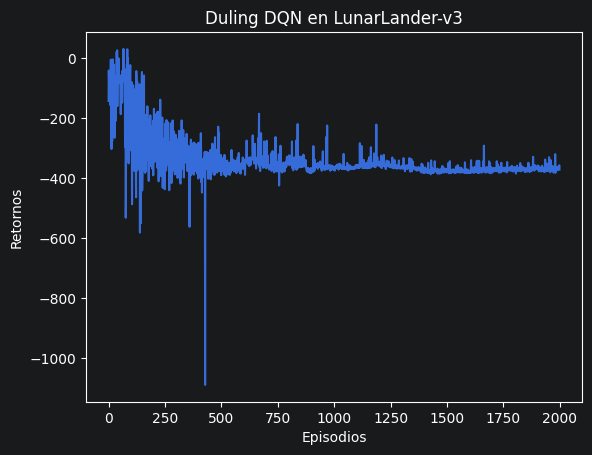

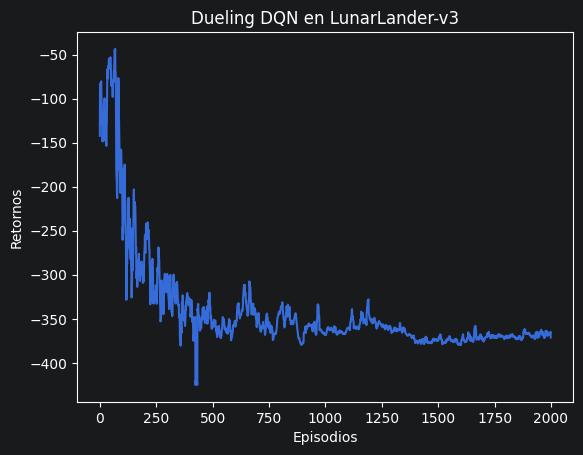

In [6]:
lr = 1e-3
num_episodes = 2000
hidden_dim = 128
gamma = 0.99
epsilon = 1
epsilon_min = 0.01
epsilon_decay = 0.995
target_update = 100
buffer_size = 100000
minimal_size = 500
batch_size = 100
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

env_name = 'LunarLander-v3'
env = gym.make(env_name)
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

# Inicializacion del Bufer de Experiencias
replay_buffer = ReplayBuffer(buffer_size)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
agent = DQN(state_dim, hidden_dim, action_dim, lr, gamma, epsilon, epsilon_min, epsilon_decay, target_update, device, 'DuelingDQN')

return_list = []
score_100 = collections.deque(maxlen = 100) # Para saber si el algoritmo resolvio el problema con un retorno alto en 100 episodios consecutivos
for i in range(10):
    with tqdm(total=int(num_episodes / 10), desc='Iteracion %d' % i) as pbar:
        for i_episode in range(int(num_episodes / 10)):
            episode_return = 0
            state, _ = env.reset(seed = 0)
            done = False
            while not done:
                action = agent.take_action(state)
                next_state,reward,terminated,truncated, _ = env.step(action)
                done = terminated or truncated
                replay_buffer.add(state, action, reward, next_state, done)
                state = next_state
                episode_return += reward
                # Cuando el numero de datos en el bufer supera un cierto valor, el entrenamiento de la Q-network es ejecutado
                if replay_buffer.size() > minimal_size:
                    b_s, b_a, b_r, b_ns, b_d =replay_buffer.sample(batch_size)
                    transition_dict = {
                        'states': b_s,
                        'actions': b_a,
                        'next_states': b_ns,
                        'rewards': b_r,
                        'dones': b_d
                    }
                    agent.update(transition_dict)
            return_list.append(episode_return)
            score_100.append(episode_return)
            agent.decay_epsilon()
            if (i_episode + 1) % 10 == 0:
                pbar.set_postfix({
                    'episodio':
                    '%d' % (num_episodes / 10 * i + i_episode + 1),
                    'retorno':
                    '%.3f' % np.mean(return_list[-10:]),
                    'epsilon':
                    '%.3f' % agent.epsilon
                })
            pbar.update(1)
            
            if np.mean(score_100) >= 200.0:
                print(f'Resuelto en {10*i + i_episode + 1} episodios')
                torch.save(agent.q_net.state_dict(), 'checkpoint.pth')
                break

episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('Duling DQN en {}'.format(env_name))
plt.show()

mv_return = moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('Dueling DQN en {}'.format(env_name))
plt.show()

# Reto 6
Pruebe la red entenada en el ambiente LunarLander-v3 y vea lo resultados.

In [7]:
#Obtener estado inicial
env = gym.make('LunarLander-v3', render_mode = 'human')
for _ in range(10):
    state, _ = env.reset()
    episode_return = 0
    done = False
    for t in range(1000):
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(device)
        # Escoger la mejor acción de la q_net
        with torch.no_grad():  # No necesitamos calcular gradientes en evaluación
            action = agent.q_net(state_tensor).max(1)[1].item()  # [1] para obtener el índice de la mejor acción
        #Obtener s', r', donde e info
        next_state,reward,terminated,truncated, _ = env.step(action)
        episode_return += reward
    
        if done:
            break
    print(f'Retorno obtenido {episode_return}')
# Cerrar el ambiente
env.close()

Retorno obtenido -92522.15586794665
Retorno obtenido -92821.07763216713
Retorno obtenido 70214.76476705947
Retorno obtenido 74417.05291330456
Retorno obtenido 74900.10927843106
Retorno obtenido 55162.568158013266
Retorno obtenido -80592.58755628308
Retorno obtenido -89954.5890424695
Retorno obtenido -91389.06168896772
Retorno obtenido -90285.68430098839


In [8]:
import io
import imageio

def show_video_of_model(agent, env_name):
    env = gym.make(env_name, render_mode='rgb_array')
    state, _ = env.reset()
    done = False
    frames = []
    while not done:
        frame = env.render()
        frames.append(frame)
        action = agent.take_action(state)
        next_state,reward,terminated,truncated, _ = env.step(action)
        done = terminated or truncated
    env.close()
    imageio.mimsave('video.mp4', frames, fps = 30, macro_block_size = 10)

show_video_of_model(agent, 'LunarLander-v3')